In [1]:
# Install the Ultralytics package (YOLOv8)
!pip install ultralytics -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 31.8 MB/s eta 0:00:00


In [2]:
import os
from pathlib import Path

from ultralytics import YOLO
from PIL import Image
import matplotlib.pyplot as plt
import yaml

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [3]:
# Mount Google Drive to access your dataset and save trained weights
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import zipfile
import os

# Path to the zip file
zip_path = '/content/drive/MyDrive/My First Project.v4i.yolov8.zip'
# Where you want to extract it
extract_path = '/content/dataset'

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Extraction complete!")

    # Update your path to the NEW extracted folder
    DRIVE_DATASET_PATH = extract_path
    DATA_YAML_PATH = os.path.join(DRIVE_DATASET_PATH, 'data.yaml')
else:
    print("Zip file not found. Check the filename (especially the .zip extension).")

Extraction complete!


In [5]:
# Load and display data.yaml contents
with open(DATA_YAML_PATH, 'r') as f:
    data_config = yaml.safe_load(f)

print("Dataset configuration:")
print(yaml.dump(data_config, default_flow_style=False))

# If paths in data.yaml are relative, we may need to update them for Colab
# Create an updated data.yaml in /content with absolute Drive paths
train_images = os.path.join(DRIVE_DATASET_PATH, 'train', 'images')
train_labels = os.path.join(DRIVE_DATASET_PATH, 'train', 'labels')

num_images = len([f for f in os.listdir(train_images) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))])
num_labels = len([f for f in os.listdir(train_labels) if f.endswith('.txt')])

print(f"\nTrain images: {num_images}")
print(f"Train labels: {num_labels}")
print(f"Classes: {data_config.get('names', 'N/A')}")

Dataset configuration:
names:
- '0'
- '1'
- '2'
- '3'
- '4'
- '5'
- '6'
- '7'
- '8'
- '9'
- A
- B
- C
- D
- E
- F
- G
- H
- I
- J
- K
- L
- M
- N
- O
- P
- Q
- R
- S
- T
- U
- V
- W
- X
- Y
- YY
- Z
- a
nc: 38
roboflow:
  license: CC BY 4.0
  project: my-first-project-dcdks
  url: https://universe.roboflow.com/remediess-workspace/my-first-project-dcdks/dataset/4
  version: 4
  workspace: remediess-workspace
test: ../test/images
train: ../train/images
val: ../valid/images


Train images: 1235
Train labels: 1235
Classes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'YY', 'Z', 'a']


In [6]:
# Create a Colab-friendly data.yaml with absolute paths (YOLO expects paths relative to project or absolute)
COLAB_DATA_YAML = '/content/data.yaml'

train_path = os.path.join(DRIVE_DATASET_PATH, 'train')
data_config['path'] = DRIVE_DATASET_PATH
data_config['train'] = train_path

# Set validation path: use only if the folder exists, otherwise use train (no separate valid folder)
val_path = None
if data_config.get('val'):
    raw_val = data_config['val']
    val_path = os.path.join(DRIVE_DATASET_PATH, raw_val) if not os.path.isabs(str(raw_val)) else raw_val
# YOLO looks for <val_path>/images; if missing, use train for validation too
val_images = os.path.join(val_path, 'images') if val_path else None
if val_images and os.path.isdir(val_images):
    data_config['val'] = val_path
else:
    data_config['val'] = train_path
    print("No separate 'valid' folder found; using 'train' for validation as well.")

with open(COLAB_DATA_YAML, 'w') as f:
    yaml.dump(data_config, f, default_flow_style=False, sort_keys=False)

print(f"Saved Colab data config to: {COLAB_DATA_YAML}")
with open(COLAB_DATA_YAML, 'r') as f:
    print(f.read())

No separate 'valid' folder found; using 'train' for validation as well.
Saved Colab data config to: /content/data.yaml
train: /content/dataset/train
val: /content/dataset/train
test: ../test/images
nc: 38
names:
- '0'
- '1'
- '2'
- '3'
- '4'
- '5'
- '6'
- '7'
- '8'
- '9'
- A
- B
- C
- D
- E
- F
- G
- H
- I
- J
- K
- L
- M
- N
- O
- P
- Q
- R
- S
- T
- U
- V
- W
- X
- Y
- YY
- Z
- a
roboflow:
  workspace: remediess-workspace
  project: my-first-project-dcdks
  version: 4
  license: CC BY 4.0
  url: https://universe.roboflow.com/remediess-workspace/my-first-project-dcdks/dataset/4
path: /content/dataset



In [7]:
# Load the YOLOv8 nano model (smallest/fastest; use yolov8s.pt, yolov8m.pt, etc. for larger models)
model = YOLO('yolov8n.pt')
print("Loaded YOLOv8n model (yolov8n.pt)")

Loaded YOLOv8n model (yolov8n.pt)


In [8]:
# Train the model
results = model.train(
    data=COLAB_DATA_YAML,
    epochs=100,
    imgsz=640,
    batch=16,
    project='/content/runs/detect',
    name='license_plate_char',
    exist_ok=True,
    pretrained=True,
    verbose=True
)

Ultralytics 8.4.27 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=license_plate_char, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspecti

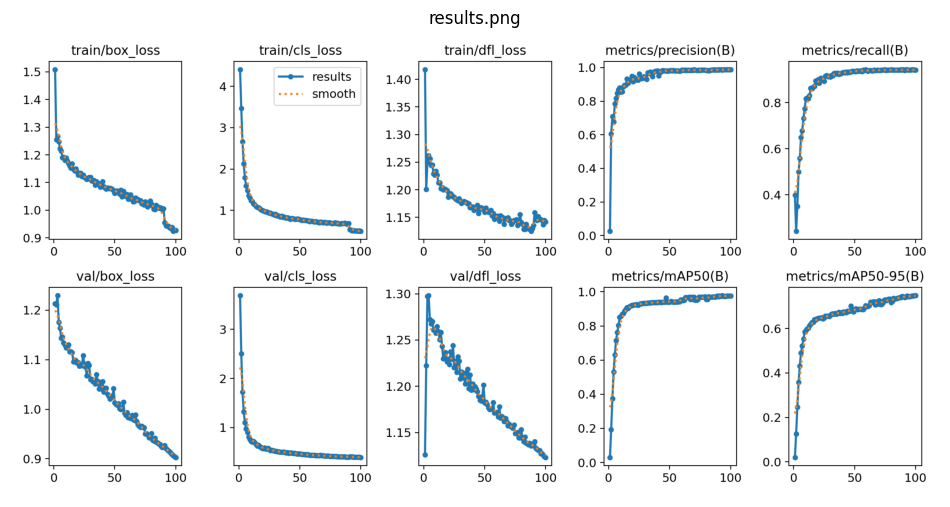

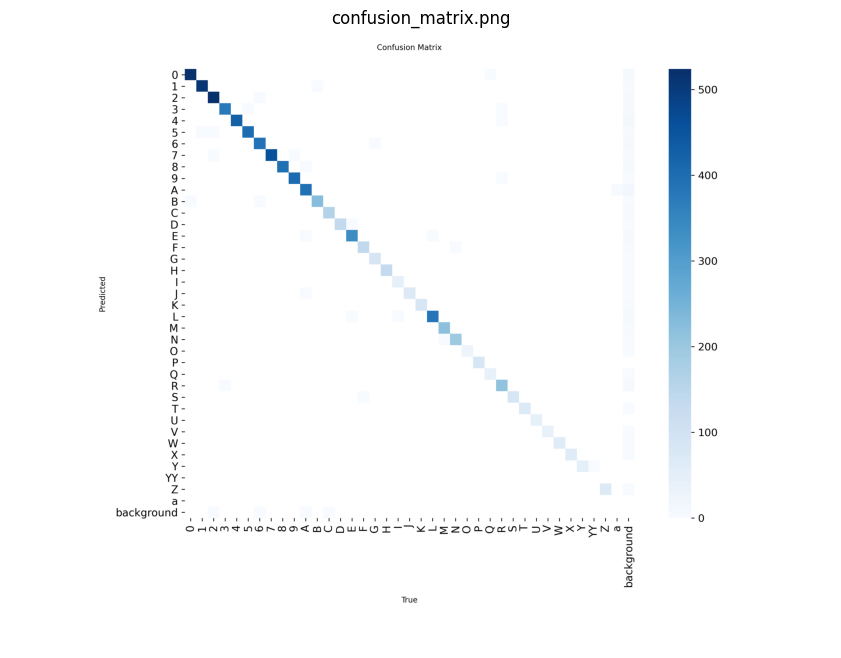

In [9]:
# Plot training results (loss curves, metrics)
results_path = Path('/content/runs/detect/license_plate_char')

# Show results images if generated
for img_file in ['results.png', 'confusion_matrix.png', 'F1_curve.png', 'PR_curve.png']:
    img_path = results_path / img_file
    if img_path.exists():
        img = Image.open(img_path)
        plt.figure(figsize=(12, 8))
        plt.imshow(img)
        plt.axis('off')
        plt.title(img_file)
        plt.show()

In [10]:
# Load the best weights from training for inference
best_weights = results_path / 'weights' / 'best.pt'
if best_weights.exists():
    model = YOLO(str(best_weights))
    print(f"Loaded best weights: {best_weights}")
else:
    print("Best weights not found; using last.pt")
    model = YOLO(str(results_path / 'weights' / 'last.pt'))

Loaded best weights: /content/runs/detect/license_plate_char/weights/best.pt


In [11]:
# Pick a few images from the training set for inference demo
sample_images_dir = Path(train_images)
image_extensions = ('.jpg', '.jpeg', '.png', '.bmp')
sample_files = [f for f in sample_images_dir.iterdir() if f.suffix.lower() in image_extensions][:6]

if not sample_files:
    print("No images found in train/images.")
else:
    print(f"Running inference on {len(sample_files)} images...")
    # Run prediction (results saved to runs/detect/predict)
    pred_results = model.predict(
        source=[str(p) for p in sample_files],
        save=True,
        project='/content/runs/detect',
        name='predict',
        exist_ok=True
    )

Running inference on 6 images...

0: 640x640 1 0, 1 1, 1 7, 1 A, 1 G, 1 R, 11.0ms
1: 640x640 1 4, 1 5, 1 8, 1 B, 1 C, 1 F, 11.0ms
2: 640x640 1 3, 1 4, 1 7, 1 9, 2 Zs, 11.0ms
3: 640x640 1 1, 1 3, 1 9, 1 M, 1 N, 11.0ms
4: 640x640 1 1, 1 2, 1 3, 1 4, 1 K, 1 R, 1 T, 11.0ms
5: 640x640 3 5s, 1 9, 2 Es, 1 L, 11.0ms
Speed: 2.9ms preprocess, 11.0ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict


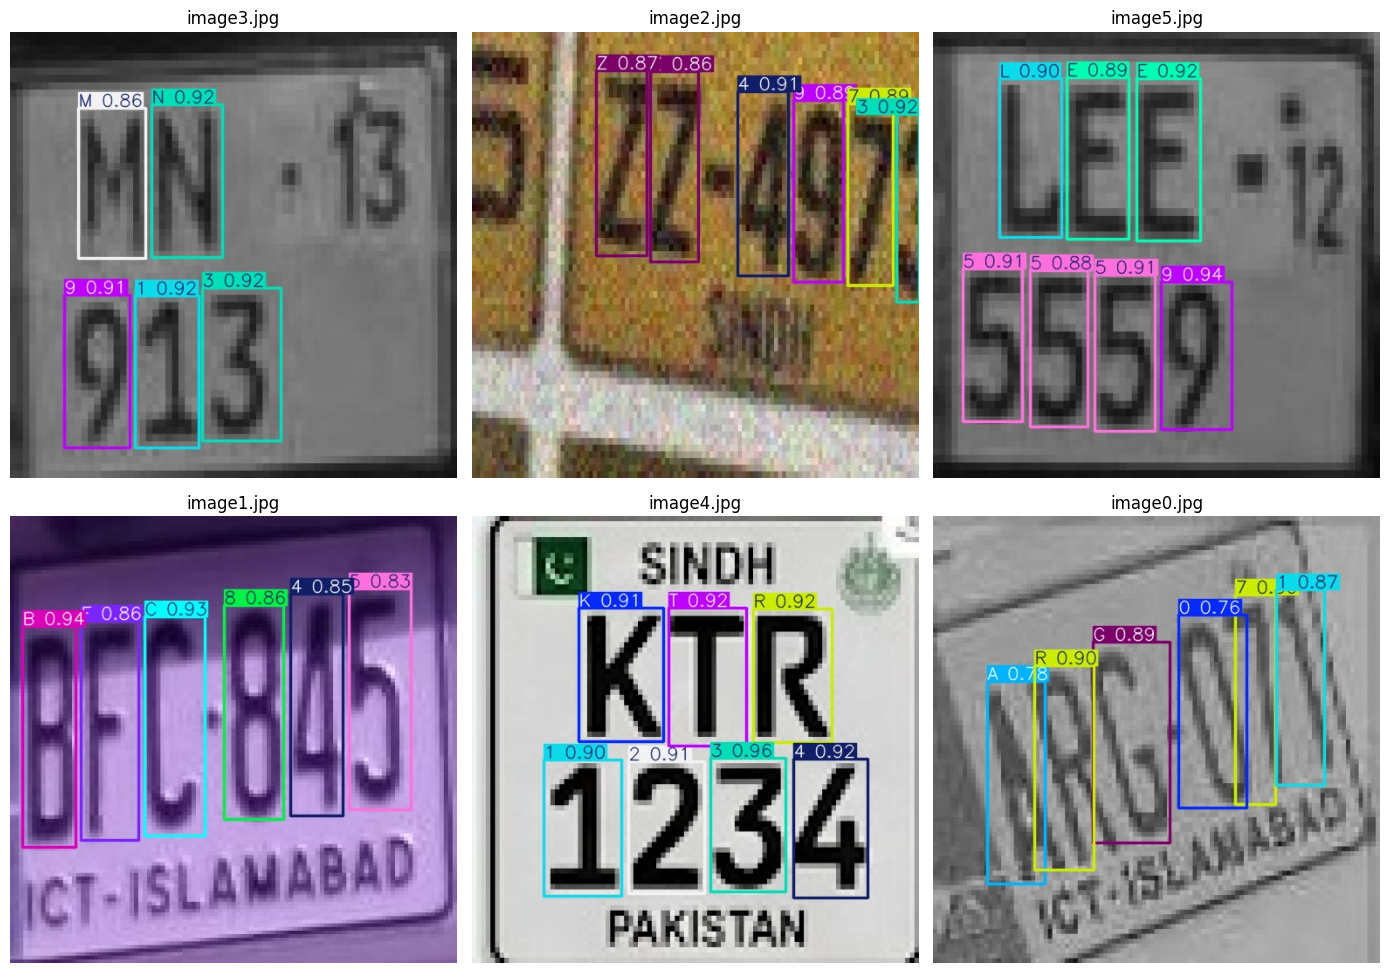

In [20]:
# Display predicted images with bounding boxes
predict_dir = Path('/content/runs/detect/predict')
saved_images = list(predict_dir.glob('*.jpg')) if predict_dir.exists() else []
if not saved_images:
    saved_images = list(predict_dir.glob('*.png'))

n_show = min(6, len(saved_images))
if n_show == 0:
    print("No saved prediction images found.")
else:
    fig, axes = plt.subplots(2, 3, figsize=(14, 10))
    axes = axes.flatten()
    for i, img_path in enumerate(saved_images[:n_show]):
        img = Image.open(img_path)
        axes[i].imshow(img)
        axes[i].set_title(img_path.name)
        axes[i].axis('off')
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')
    plt.tight_layout()
    plt.show()

In [13]:
# Copy best and last weights to Google Drive
import shutil

OUTPUT_DRIVE_DIR = '/content/drive/MyDrive/yolov8_license_plate_weights'
os.makedirs(OUTPUT_DRIVE_DIR, exist_ok=True)

weights_dir = results_path / 'weights'
for wfile in ['best.pt', 'last.pt']:
    src = weights_dir / wfile
    if src.exists():
        dst = os.path.join(OUTPUT_DRIVE_DIR, wfile)
        shutil.copy2(src, dst)
        print(f"Saved {wfile} to {dst}")

print(f"\nAll weights saved to: {OUTPUT_DRIVE_DIR}")

Saved best.pt to /content/drive/MyDrive/yolov8_license_plate_weights/best.pt
Saved last.pt to /content/drive/MyDrive/yolov8_license_plate_weights/last.pt

All weights saved to: /content/drive/MyDrive/yolov8_license_plate_weights


Ultralytics 8.4.27 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,013,058 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1053.0±369.2 MB/s, size: 33.2 KB)
val: Scanning /content/dataset/train/labels.cache... 1235 images, 6 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1235/1235 246.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 78/78 5.3it/s 14.6s
                   all       1235       7883       0.99      0.942      0.977      0.749
Speed: 1.4ms preprocess, 4.0ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /content/runs/detect/val


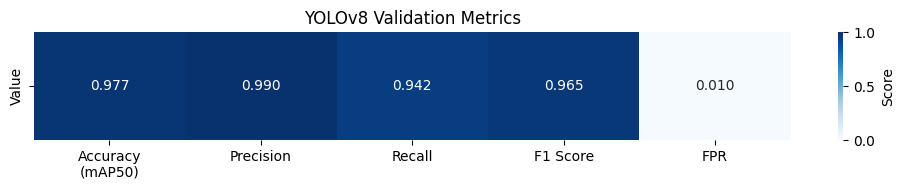

In [14]:
# Cell 1 — Performance Heatmap (uses validation metrics; no CSV needed)
# Uses results_path and COLAB_DATA_YAML from earlier cells. Run Section 5 and 8 first.
import seaborn as sns
import numpy as np

# Same run directory as in Section 8 (Display Training Results)
results_path = Path('/content/runs/detect/license_plate_char')
best_pt = results_path / 'weights' / 'best.pt'
if not best_pt.exists():
    raise FileNotFoundError(f"best.pt not found at {best_pt}. Train the model first.")

# Load trained model and run validation to get metrics
model = YOLO(str(best_pt))
val_metrics = model.val(data=COLAB_DATA_YAML, verbose=False)

# Extract metrics from validation result (Ultralytics DetectionMetrics)
precision = float(val_metrics.box.mp)
recall = float(val_metrics.box.mr)
mAP50 = float(val_metrics.box.map50)

# Derive: Accuracy = mAP50; F1; FPR = 1 - precision
accuracy = mAP50
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
fpr = 1.0 - precision

metrics_names = ['Accuracy\n(mAP50)', 'Precision', 'Recall', 'F1 Score', 'FPR']
metrics_values = [accuracy, precision, recall, f1, fpr]

# Heatmap
matrix = np.array(metrics_values).reshape(1, -1)
fig, ax = plt.subplots(figsize=(10, 2))
sns.heatmap(matrix, annot=True, fmt='.3f', cmap='Blues', xticklabels=metrics_names,
            yticklabels=['Value'], cbar_kws={'label': 'Score'}, ax=ax, vmin=0, vmax=1)
ax.set_title('YOLOv8 Validation Metrics')
plt.tight_layout()
plt.show()

In [21]:
def fix_license_plate_format(detections):
    """
    Post-process YOLO character detections into a standard license plate string.
    Format: 3 letters + '-' + 3 or 4 digits (e.g. LER-1234, ABC-987, LEA-17).
    Removes misordered or extra characters: first part must be letters, last part must be digits.

    Args:
        detections: list of (class_name, x_center).
            class_name: str (e.g. 'A', '1'). Can be from model.names[cls].
            x_center: float, center x of bounding box (e.g. (x1+x2)/2).

    Returns:
        Corrected plate string, e.g. 'LER-1234', 'ABC-987'.
    """
    LETTERS = set('ABCDEFGHIJKLMNOPQRSTUVWXYZ')
    DIGITS = set('0123456789')
    MAX_LETTERS = 3
    MAX_DIGITS = 4

    letters = []
    digits = []
    for c, x in detections:
        c = str(c).strip().upper()
        if c in LETTERS:
            letters.append((c, x))
        elif c in DIGITS:
            digits.append((c, x))
    # Sort left to right by x
    letters.sort(key=lambda t: t[1])
    digits.sort(key=lambda t: t[1])

    # First 3 letters (leftmost)
    letters_str = ''.join(c for c, _ in letters[:MAX_LETTERS])
    # Last 3 or 4 digits (rightmost); prefer 4 if we have 4, else 3
    digits_str = ''.join(c for c, _ in digits[-MAX_DIGITS:])

    if not letters_str and not digits_str:
        return ''
    if not digits_str:
        return letters_str
    if not letters_str:
        return digits_str
    return letters_str + '-' + digits_str


Saving camA_413_jpg.rf.95899b34d3aeedce2618e5edbf4e391e.jpg to camA_413_jpg.rf.95899b34d3aeedce2618e5edbf4e391e (1).jpg
Detected (raw): LL09614
Corrected plate: LL-0149


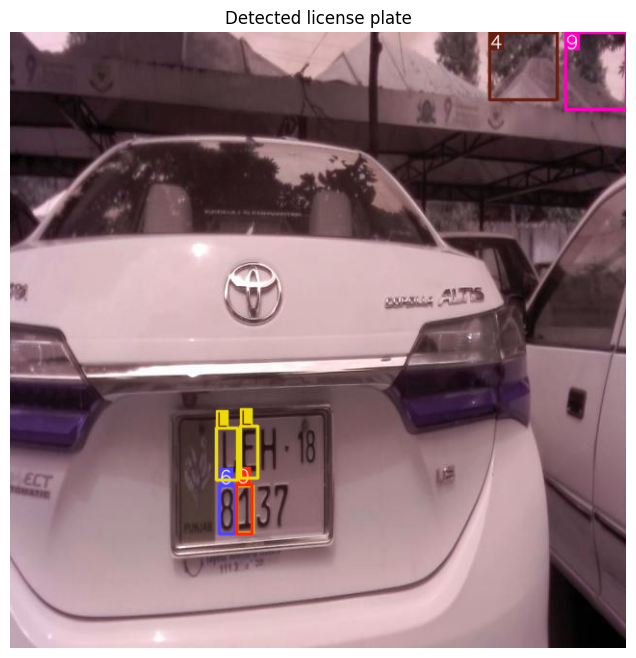

In [23]:
# Cell 2 — Upload Image and Predict License Plate
import numpy as np
from google.colab import files

# Auto-detect run folder (train, license_plate_char, or first folder with best.pt)
detect_runs = Path('/content/runs/detect')
best_pt = None
if detect_runs.exists():
    for run_dir in sorted(detect_runs.iterdir()):
        if run_dir.is_dir():
            w = run_dir / 'weights' / 'best.pt'
            if w.exists():
                best_pt = w
                break
if best_pt is None:
    raise FileNotFoundError("best.pt not found under /content/runs/detect/. Train the model first (Section 7).")
model = YOLO(str(best_pt))

# Upload an image from your device
uploaded = files.upload()
if not uploaded:
    print("No file uploaded. Run the cell again and select an image.")
else:
    # Run inference on the first uploaded image
    img_path = list(uploaded.keys())[0]
    # Ultralytics does not accept .jfif; convert to .jpg if needed
    supported = {'jpg', 'jpeg', 'png', 'bmp', 'webp', 'tif', 'tiff'}
    if Path(img_path).suffix.lower().lstrip('.') not in supported:
        from PIL import Image
        tmp_path = '/content/uploaded_image.jpg'
        Image.open(img_path).convert('RGB').save(tmp_path, 'JPEG')
        img_path = tmp_path
    results = model.predict(source=img_path, save=False, verbose=False)

    # Use detection order (first detected = first in string); show image with boxes
    for r in results:
        boxes = r.boxes
        if boxes is None or len(boxes) == 0:
            print("No characters or digits detected.")
            continue
        xyxy = boxes.xyxy.cpu().numpy()
        cls = boxes.cls.cpu().numpy().astype(int)
        # Build (class_name, x_center) for post-processing
        x_centers = (xyxy[:, 0] + xyxy[:, 2]) / 2
        detections = [(model.names[i], float(x_centers[j])) for j, i in enumerate(cls)]
        raw_str = ''.join(c for c, _ in detections)
        corrected_str = fix_license_plate_format(detections)
        print("Detected (raw):", raw_str)
        print("Corrected plate:", corrected_str)
        # Show image with bounding boxes (class names only, no confidence)
        annotated = r.plot(conf=False)
        plt.figure(figsize=(10, 8))
        plt.imshow(annotated)
        plt.axis('off')
        plt.title('Detected license plate')
        plt.show()

In [24]:
# Cell 3 — Download Runs Folder
import zipfile
from google.colab import files

RUNS_DIR = '/content/runs'
ZIP_NAME = 'runs_folder.zip'

# Compress the entire /content/runs folder into a ZIP file
with zipfile.ZipFile(ZIP_NAME, 'w', zipfile.ZIP_DEFLATED) as zf:
    for root, dirs, filenames in os.walk(RUNS_DIR):
        for f in filenames:
            path = os.path.join(root, f)
            arcname = os.path.relpath(path, os.path.dirname(RUNS_DIR))
            zf.write(path, arcname)

print(f"Created {ZIP_NAME}. Downloading...")
files.download(ZIP_NAME)
print("Download started. Save the file when your browser prompts.")

Created runs_folder.zip. Downloading...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started. Save the file when your browser prompts.
